<a href="https://colab.research.google.com/github/Fath-fanoon/EcoCred/blob/main/diabetes_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
from sklearn.datasets import fetch_openml

data = fetch_openml('diabetes', version=1, as_frame=True)
df = data.frame

print(df.shape)
print(df['class'].value_counts())
df.head()

(768, 9)
class
tested_negative    500
tested_positive    268
Name: count, dtype: int64


,preg,plas,pres,skin,insu,mass,pedi,age,class
0,6,148,72,35,0,33.6,0.627,50,tested_positive
1,1,85,66,29,0,26.6,0.351,31,tested_negative
2,8,183,64,0,0,23.3,0.672,32,tested_positive
3,1,89,66,23,94,28.1,0.167,21,tested_negative
4,0,137,40,35,168,43.1,2.288,33,tested_positive


In [2]:
# Rename columns to readable names
df = df.rename(columns={
    'preg': 'pregnancies', 'plas': 'glucose', 'pres': 'blood_pressure',
    'skin': 'skin_thickness', 'insu': 'insulin', 'mass': 'bmi',
    'pedi': 'diabetes_pedigree', 'age': 'age', 'class': 'diabetic'
})

# Turn the target into 0/1
df['diabetic'] = (df['diabetic'] == 'tested_positive').astype(int)

# These columns can't really be 0, so treat zeros as missing
cols_with_fake_zeros = ['glucose', 'blood_pressure', 'skin_thickness', 'insulin', 'bmi']
df[cols_with_fake_zeros] = df[cols_with_fake_zeros].replace(0, np.nan)

# How much is missing in each column?
print(df.isna().sum())
print()
print(df.describe().round(1))

pregnancies            0
glucose                5
blood_pressure        35
skin_thickness       227
insulin              374
bmi                   11
diabetes_pedigree      0
age                    0
diabetic               0
dtype: int64

       pregnancies  glucose  blood_pressure  skin_thickness  insulin    bmi  \
count        768.0    763.0           733.0           541.0    394.0  757.0   
mean           3.8    121.7            72.4            29.2    155.5   32.5   
std            3.4     30.5            12.4            10.5    118.8    6.9   
min            0.0     44.0            24.0             7.0     14.0   18.2   
25%            1.0     99.0            64.0            22.0     76.2   27.5   
50%            3.0    117.0            72.0            29.0    125.0   32.3   
75%            6.0    141.0            80.0            36.0    190.0   36.6   
max           17.0    199.0           122.0            99.0    846.0   67.1   

       diabetes_pedigree    age  diabetic  
count

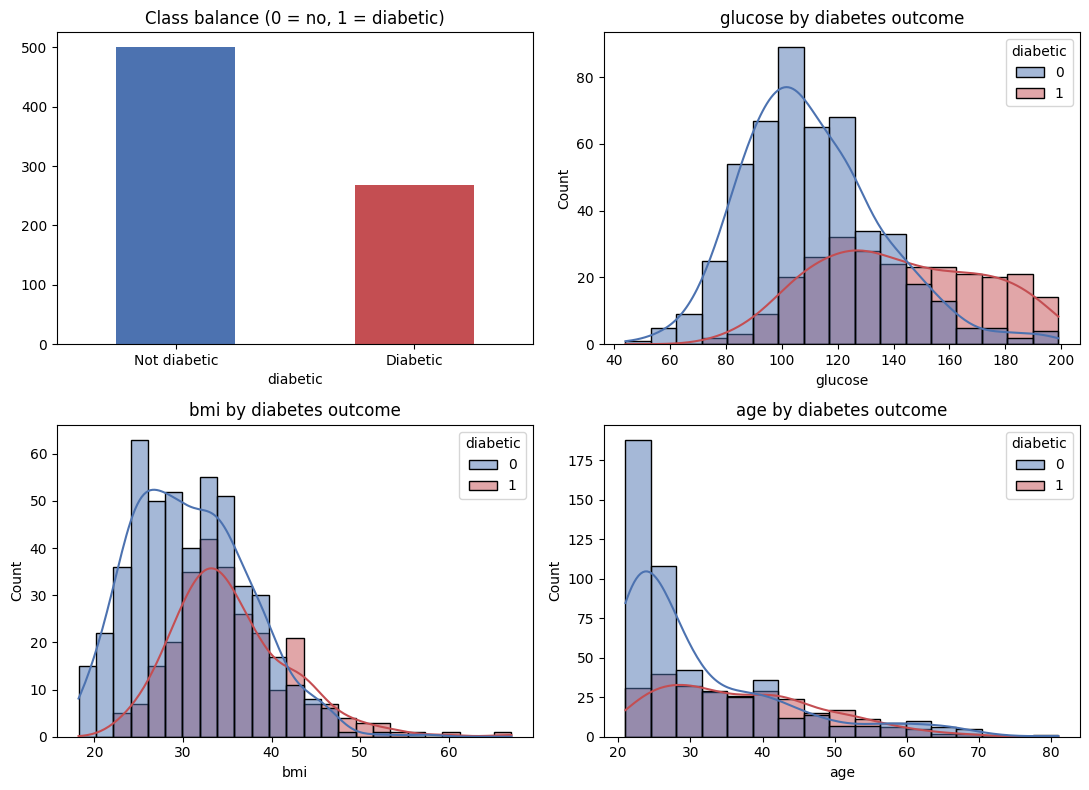

glucose              0.49
bmi                  0.31
insulin              0.30
skin_thickness       0.26
age                  0.24
pregnancies          0.22
diabetes_pedigree    0.17
blood_pressure       0.17
Name: diabetic, dtype: float64


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(11, 8))

# 1. Class balance
df['diabetic'].value_counts().plot(kind='bar', ax=axes[0, 0], color=['#4C72B0', '#C44E52'])
axes[0, 0].set_title('Class balance (0 = no, 1 = diabetic)')
axes[0, 0].set_xticklabels(['Not diabetic', 'Diabetic'], rotation=0)

# 2-4. Distributions by outcome
for ax, col in zip([axes[0, 1], axes[1, 0], axes[1, 1]], ['glucose', 'bmi', 'age']):
    sns.histplot(data=df, x=col, hue='diabetic', kde=True, ax=ax, palette=['#4C72B0', '#C44E52'])
    ax.set_title(f'{col} by diabetes outcome')

plt.tight_layout()
plt.show()

# Correlation of each feature with the outcome
print(df.corr()['diabetic'].drop('diabetic').sort_values(ascending=False).round(2))

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

X = df.drop(columns='diabetic')
y = df['diabetic']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

models = {
    'Baseline (always "no")': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
        ('model', LogisticRegression(max_iter=1000))
    ]),
    'Random Forest': Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('model', RandomForestClassifier(n_estimators=200, random_state=42))
    ]),
}

# The dummy model can't handle NaN, so give it a simple filled copy
X_train_filled = X_train.fillna(X_train.median())
X_test_filled = X_test.fillna(X_train.median())

results = []
for name, model in models.items():
    if name.startswith('Baseline'):
        model.fit(X_train_filled, y_train)
        pred = model.predict(X_test_filled)
        proba = model.predict_proba(X_test_filled)[:, 1]
    else:
        model.fit(X_train, y_train)
        pred = model.predict(X_test)
        proba = model.predict_proba(X_test)[:, 1]
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'ROC-AUC': roc_auc_score(y_test, proba),
    })

results_df = pd.DataFrame(results).round(3)
print(results_df.to_string(index=False))

                 Model  Accuracy  Precision  Recall    F1  ROC-AUC
Baseline (always "no")     0.649      0.000   0.000 0.000    0.500
   Logistic Regression     0.708      0.600   0.500 0.545    0.813
         Random Forest     0.740      0.652   0.556 0.600    0.817


5-fold cross-validation (mean ± std)

Logistic Regression
  roc_auc  0.837 ± 0.020
  recall   0.571 ± 0.047
  f1       0.636 ± 0.021

Random Forest
  roc_auc  0.826 ± 0.021
  recall   0.612 ± 0.035
  f1       0.645 ± 0.035



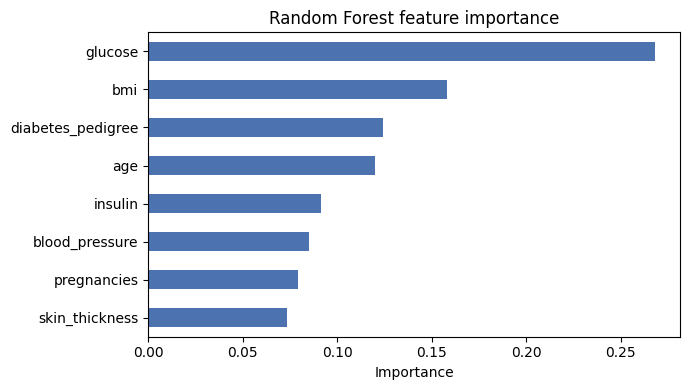

glucose              0.268
bmi                  0.158
diabetes_pedigree    0.124
age                  0.120
insulin              0.092
blood_pressure       0.085
pregnancies          0.079
skin_thickness       0.073
dtype: float64


In [6]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ['roc_auc', 'recall', 'f1']

print("5-fold cross-validation (mean ± std)\n")
for name in ['Logistic Regression', 'Random Forest']:
    scores = cross_validate(models[name], X, y, cv=cv, scoring=scoring)
    print(name)
    for metric in scoring:
        vals = scores[f'test_{metric}']
        print(f"  {metric:8s} {vals.mean():.3f} ± {vals.std():.3f}")
    print()

# Feature importance from the random forest trained earlier
rf = models['Random Forest'].named_steps['model']
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values()

importance.plot(kind='barh', figsize=(7, 4), color='#4C72B0')
plt.title('Random Forest feature importance')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

print(importance.sort_values(ascending=False).round(3))